# Transits of a limb-polarised star in Stokes I, Q and U

This notebook is a minimal working example of the `transit_polarization` package in this folder. It assumes you know how an ordinary transit light curve is computed: a star has a limb-darkened intensity profile $I(\mu)$, an opaque planet crosses it, and the light curve is the fraction of the disk-integrated flux that the planet leaves visible. Here we do exactly the same thing for polarised light.

The physics in one paragraph. In the continuum of an F, G or K star, light emerging close to the limb has a significant contribution from scattering (Rayleigh scattering on H I and H$_2$, Thomson scattering on free electrons), so it is weakly linearly polarised, with the electric vector parallel to the limb. Kostogryz & Berdyugina (2015, A&A 575, A89; "K&B" below) computed this centre-to-limb variation of polarisation for a grid of FGK model atmospheres. Integrated over the whole disk the polarisation cancels by symmetry, so an unresolved star is unpolarised. A transiting planet breaks that symmetry by hiding a patch of the disk, and the light it leaves behind carries a net linear polarisation of order parts per million.

By the end you should understand four things: how K&B's tables map onto jaxoplanet's polynomial limb-darkening law, including the normalisations that are easy to get wrong; why the sky-frame Stokes $Q$ and $U$ maps of such a star are exactly starry spherical-harmonic maps, so jaxoplanet can occult them analytically; what the transit signal looks like in $I$, $Q$, $U$ and the degree of polarisation, and how it depends on stellar type; and how to estimate whether a telescope can detect it in the photon-noise limit. `README.md` in the folder above is the longer reference version of every convention used here.

In [1]:
import sys
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
from jaxoplanet.orbits import TransitOrbit
from matplotlib.colors import SymLogNorm
from tqdm.auto import tqdm

try:
    import transit_polarization as tp
except ImportError:  # running from notebooks/ without `pip install -e ..`
    sys.path.insert(0, str(Path.cwd().parent))
    import transit_polarization as tp

jax.config.update("jax_enable_x64", True)  # ppm-level signals need double precision
plt.rcParams.update({"font.size": 12.5, "figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

grid = tp.load_kb2015()  # bundled copy of K&B Tables 1 and 2 (VizieR J/A+A/575/A89)
print(f"wavelengths   : {grid.wavelength.astype(int)} Å")
print(f"Teff          : {grid.teff[0]:.0f}–{grid.teff[-1]:.0f} K in {grid.teff.size} steps")
print(f"log g         : {grid.logg}")
print(f"mu tabulated  : {grid.mu}  (+ mu = 1 implicitly)")

wavelengths   : [4000 4500 5000 6000 7000] Å
Teff          : 4500–6900 K in 25 steps
log g         : [3.  3.5 4.  4.5 5. ]
mu tabulated  : [0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.5  0.7  0.9 ]  (+ mu = 1 implicitly)


## 1. From the K&B tables to jaxoplanet polynomials

**The coordinate $\mu$.** K&B and jaxoplanet (like exoplanet and starry; Agol, Luger & Foreman-Mackey 2020) all use $\mu = \cos\theta$, where $\theta$ is the angle between the local surface normal and the line of sight. A point at projected distance $r$ (in stellar radii) from disk centre has $\mu = \sqrt{1 - r^2}$, so $\mu = 1$ at disk centre and $\mu = 0$ at the limb. In starry's notation $\mu$ is simply the $z$ coordinate of the visible hemisphere. No conversion is needed between the two codes.

**Intensity.** jaxoplanet's limb-darkening law is $I(\mu)/I(1) = 1 - \sum_n u_n (1-\mu)^n$. K&B Table 1 gives $I(\mu)/I(1)$ at ten values of $\mu$ from 0.1 to 0.9, and $I/I(1) = 1$ at $\mu = 1$ by definition. That normalisation to disk centre is exactly what `jaxoplanet.experimental.calc_poly_coeffs` assumes (it pins the constant term to 1), so Table 1 goes straight in. It is *not* the normalisation of a light curve, though. jaxoplanet divides by the disk-integrated flux $F_0 = \pi I(1)\,[1 - \sum_n 2u_n/((n+1)(n+2))]$, which for a real star is about $2.4\,I(1)R_\star^2$ rather than $\pi\,I(1)R_\star^2$. Confusing $I(1)$ with $F_0/\pi$ is the easiest way to get a transit polarisation amplitude wrong by tens of per cent.

**Polarisation.** K&B Table 2 gives the *degree* of polarisation $Q/I$ in a local frame aligned with the limb, where positive means the electric vector is parallel to the limb. In that frame Stokes $U$ is identically zero, because a plane-parallel, unmagnetised atmosphere is mirror-symmetric about the plane containing the line of sight and the local normal. "Polarisation perpendicular to the limb" is therefore not a separate $U$ component: it is just negative $Q$ in this frame. A non-zero limb-frame $U$ (polarisation at 45° to the limb) would need something that breaks the mirror symmetry, such as magnetic fields via the Hanle effect or horizontally inhomogeneous structure.

Degrees of polarisation do not add up across the disk, but Stokes intensities do. So we work with the limb-frame *polarised intensity*, which we write $\mathcal{Q}$ ("script Q") to keep it apart from sky-frame Stokes $Q$:

$$\mathcal{Q}(\mu) = \left[\frac{Q}{I}\right]_{\rm Table\,2}\!(\mu)\times\left[\frac{I}{I(1)}\right]_{\rm Table\,1}\!(\mu)\qquad\text{in units of } I(1).$$

**Why $\mathcal{Q} = (1-\mu^2)\,g(\mu)$.** At disk centre the direction "parallel to the limb" is undefined, so a smooth polarisation field must vanish there like $r^2 = 1-\mu^2$. We therefore fit $\mathcal{Q}(\mu) = (1-\mu^2)\,g(\mu)$ with $g(\mu) = g_1[1 - \sum_n v_n(1-\mu)^n]$, the same polynomial form as the intensity law. Both fits are ordinary linear least squares to the ten tabulated points, with $\mu = 1$ satisfied exactly by construction, and both use degree 6 by default. The next cell builds the model for a Sun-like star at the Bessell $B$ pivot wavelength (4377 Å, linearly interpolated between the 4000 and 4500 Å tables) and prints the numbers everything else depends on.

In [2]:
star = tp.LimbPolarizationModel.from_kb2015(teff=5800, logg=4.5, wavelength=4377)
print("intensity law  u_n =", np.array2string(star.u, precision=4))
print(f"g(mu = 1)      g1  = {star.g1:.4e}   [I(1)]")
print("g shape        v_n =", np.array2string(star.v, precision=2))
print(f"disk flux      F0  = {star.total_flux:.4f}   [I(1) R*^2]   (uniform disk: pi = {np.pi:.4f})")
print(f"at mu = 0.1:   QQ  = {float(star.polarized_intensity(0.1)):.3e} [I(1)],   Q/I = {float(star.pol_degree(0.1)):.3%}")

intensity law  u_n = [ 0.5923  0.3668 -0.9824  2.6714 -3.147   1.3397]
g(mu = 1)      g1  = 2.4728e-04   [I(1)]
g shape        v_n = [  13.21  -90.33  285.2  -470.61  391.25 -130.82]
disk flux      F0  = 2.3989   [I(1) R*^2]   (uniform disk: pi = 3.1416)
at mu = 0.1:   QQ  = 3.986e-04 [I(1)],   Q/I = 0.143%


The large, alternating $v_n$ are expected: $g$ rises steeply towards the limb, and a degree-6 polynomial in $(1-\mu)$ reproduces that with strong cancellations between terms. starry handles this polynomial in closed form in double precision, and the unit tests check its occultations against brute-force integration, so the cancellation does no harm.

### Do the polynomials reproduce the tables?

The figure compares the fitted polynomials (lines) with the tabulated values (open circles) for four stellar types at 4500 Å, a tabulated wavelength, so every circle is a published number rather than an interpolation. The top row shows the intensity profile and the degree of polarisation on a log scale. The bottom row shows signed residuals, polynomial minus table: in units of $10^{-4}\,I(1)$ for the intensity, and as a percentage of the peak $\mathcal{Q}$ for the polarised intensity, which is the quantity actually fitted. These are not z-scores, because the tables carry no uncertainties. Table 1 is rounded to $10^{-4}$, so residuals of that size are at the rounding limit. The grey band ($\mu<0.1$) has no tabulated data, and the polynomials are extrapolating there. The same comparison over all 625 models is the unit test `tests/test_kb2015_fits.py::test_polynomials_reproduce_every_table_model`, whose worst cases are $2.5\times10^{-4}$ in $I/I(1)$ and 0.25 % of peak $\mathcal{Q}$.

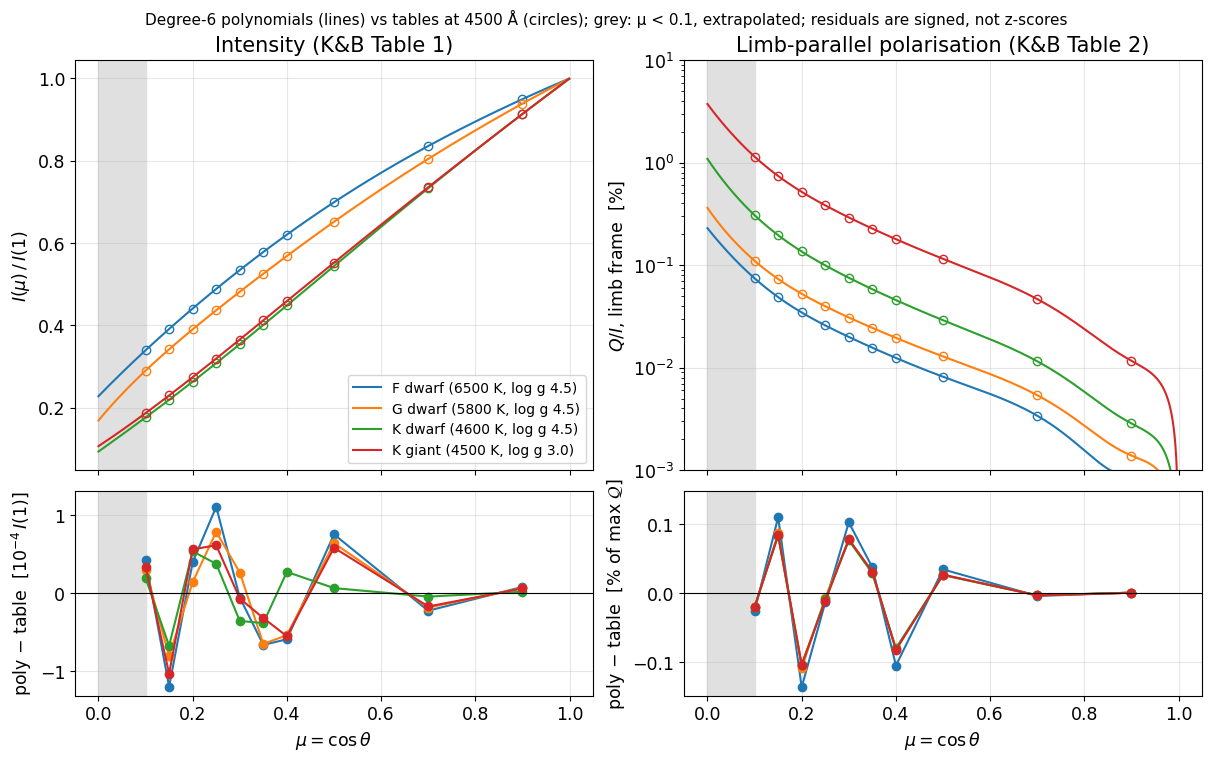

In [3]:
types = {"F dwarf (6500 K, log g 4.5)": (6500, 4.5), "G dwarf (5800 K, log g 4.5)": (5800, 4.5),
         "K dwarf (4600 K, log g 4.5)": (4600, 4.5), "K giant (4500 K, log g 3.0)": (4500, 3.0)}
mu = np.linspace(0, 0.999, 500)
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]}, constrained_layout=True)
for (label, (teff, logg)), c in zip(types.items(), plt.cm.tab10.colors):
    m = tp.LimbPolarizationModel.from_kb2015(teff, logg, wavelength=4500, grid=grid)
    tab_mu, tab_i, tab_p = m.table["mu"], m.table["intensity"], m.table["pol_degree"]
    ax[0, 0].plot(mu, m.intensity(mu), color=c, label=label)
    ax[0, 0].plot(tab_mu, tab_i, "o", mfc="none", color=c)
    ax[0, 1].semilogy(mu, 100 * m.pol_degree(mu), color=c)
    ax[0, 1].plot(tab_mu, 100 * tab_p, "o", mfc="none", color=c)
    ax[1, 0].plot(tab_mu, 1e4 * (m.intensity(tab_mu) - tab_i), "o-", color=c)
    ax[1, 1].plot(tab_mu, 100 * (m.polarized_intensity(tab_mu) - tab_p * tab_i) / (tab_p * tab_i).max(), "o-", color=c)
for a in ax.ravel():
    a.axvspan(0, 0.1, color="0.88", zorder=0)
for a in ax[1]:
    lim = np.abs(a.get_ylim()).max()
    a.set_ylim(-lim, lim)
    a.axhline(0, color="k", lw=0.8)
ax[0, 0].set(ylabel=r"$I(\mu)\,/\,I(1)$", title="Intensity (K&B Table 1)")
ax[0, 0].legend(fontsize=10)
ax[0, 1].set(ylabel=r"$Q/I$, limb frame  [%]", title="Limb-parallel polarisation (K&B Table 2)", ylim=(1e-3, 10))
ax[1, 0].set(xlabel=r"$\mu = \cos\theta$", ylabel=r"poly − table  [$10^{-4}\,I(1)$]")
ax[1, 1].set(xlabel=r"$\mu = \cos\theta$", ylabel=r"poly − table  [% of max $\mathcal{Q}$]")
fig.suptitle("Degree-6 polynomials (lines) vs tables at 4500 Å (circles); grey: μ < 0.1, extrapolated; residuals are signed, not z-scores", fontsize=11);

## 2. From the limb frame to the sky: Stokes maps that starry can occult

Put the polarimeter's reference axis along $x$, the planet's direction of motion on the sky, with $y$ perpendicular to it (this is the frame of `jaxoplanet.orbits.TransitOrbit`, in which the planet crosses at $y = b$). Sky-frame Stokes parameters are $Q = I_x - I_y$ and $U = I_{+45^\circ} - I_{-45^\circ}$, with angles measured from $+x$ towards $+y$. A point on the disk at position angle $\varphi$ has limb-parallel polarisation at angle $\varphi + 90^\circ$, so it contributes

$$Q_{\rm sky} = \mathcal{Q}\cos(2\varphi + 180^\circ) = -\mathcal{Q}\cos 2\varphi, \qquad U_{\rm sky} = -\mathcal{Q}\sin 2\varphi .$$

With $\cos 2\varphi = (x^2-y^2)/r^2$, $\sin 2\varphi = 2xy/r^2$ and $\mathcal{Q} = r^2 g(\mu)$, the $r^2$ cancels:

$$Q_{\rm sky}(x,y) = -g(\mu)\,(x^2-y^2), \qquad U_{\rm sky}(x,y) = -2\,g(\mu)\,x y .$$

On the sphere, $x^2-y^2$ and $xy$ are the $l=2$, $m=\pm2$ spherical harmonics, and $g(\mu)$ has exactly the form of a polynomial limb-darkening law. So each Stokes map is a starry `Surface` with a single $Y_{2,\pm2}$ coefficient and "limb-darkening" coefficients $v_n$, and jaxoplanet can compute its occultation by a planet exactly. That is all `tp.stokes_surfaces` does. The images below show the three maps for the G dwarf. The cyan ticks on the intensity map mark the local polarisation direction, with length proportional to $Q/I$ (greatly exaggerated). The $Q$ and $U$ colour scales are symmetric-logarithmic: diverging and centred on zero, linear within ±1 % of the peak and logarithmic beyond. Without that, the steep rise at the limb would wash out the $\cos 2\varphi$ and $\sin 2\varphi$ patterns in the interior. Light grey marks pixels off the disk. The axes are the transit frame, not North/East on the sky; `tp.rotate_stokes` converts $(Q, U)$ to any polarimeter frame.

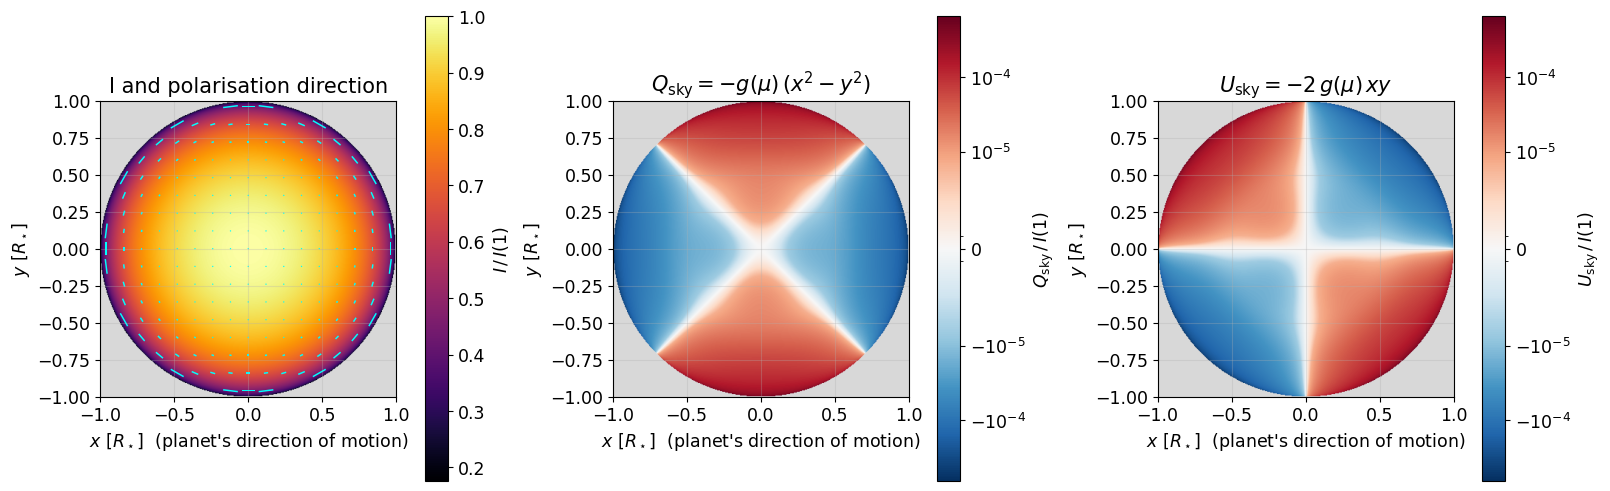

In [4]:
x, y, I_map, Q_map, U_map = tp.stokes_images(star, res=401)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
seq, div = plt.get_cmap("inferno").copy(), plt.get_cmap("RdBu_r").copy()
seq.set_bad("0.85"), div.set_bad("0.85")
im = ax[0].imshow(I_map, origin="lower", extent=(-1, 1, -1, 1), cmap=seq)
fig.colorbar(im, ax=ax[0], label=r"$I\,/\,I(1)$")
gx, gy = np.meshgrid(np.linspace(-0.96, 0.96, 17), np.linspace(-0.96, 0.96, 17))
inside = np.hypot(gx, gy) < 0.98
p_loc = np.asarray(star.pol_degree(np.sqrt(1 - gx[inside] ** 2 - gy[inside] ** 2)))
length, phi = 0.1 * p_loc / p_loc.max(), np.arctan2(gy[inside], gx[inside]) + np.pi / 2  # tangential
ax[0].quiver(gx[inside], gy[inside], length * np.cos(phi), length * np.sin(phi), color="cyan", pivot="middle",
             angles="xy", scale_units="xy", scale=1, headwidth=0, headlength=0, headaxislength=0, width=0.005)
vmax = np.nanmax(np.abs(Q_map))
norm = SymLogNorm(linthresh=vmax / 100, vmin=-vmax, vmax=vmax)  # diverging, centred on zero
for a, m, lab in [(ax[1], Q_map, r"$Q_{\rm sky}\,/\,I(1)$"), (ax[2], U_map, r"$U_{\rm sky}\,/\,I(1)$")]:
    im = a.imshow(m, origin="lower", extent=(-1, 1, -1, 1), cmap=div, norm=norm)
    fig.colorbar(im, ax=a, label=lab, ticks=[-1e-4, -1e-5, 0, 1e-5, 1e-4])
titles = ["I and polarisation direction", r"$Q_{\rm sky} = -g(\mu)\,(x^2 - y^2)$", r"$U_{\rm sky} = -2\,g(\mu)\,xy$"]
for a, title in zip(ax, titles):
    a.set(xlabel=r"$x$ [$R_\star$]  (planet's direction of motion)", ylabel=r"$y$ [$R_\star$]", title=title, aspect="equal")

### Checking the normalisation by brute force

Three normalisation traps sit between those maps and a correct light curve, and the package handles each explicitly. First, starry's spherical harmonics are $2/\sqrt{\pi}$ times the orthonormal ones, so $Y_{0,0} = 1/\pi$ (a uniform disk of unit flux), $Y_{2,2} = \tfrac{\sqrt{15}}{2\pi}(x^2-y^2)$ and $Y_{2,-2} = \tfrac{\sqrt{15}}{\pi}xy$. Second, `jaxoplanet.starry.light_curves.surface_light_curve` divides every limb-darkened map by $F_v = \frac{1}{\pi}\int_{\rm disk}[1-\sum v_n(1-\mu)^n]\,dA = 1 - \sum 2v_n/((n+1)(n+2))$, so that limb darkening never changes the total flux of a $Y_{0,0}$ map. That is harmless for intensity. For our $Q$ map, though, the "limb darkening" is $g$, so we must multiply $F_v$ back in. Forgetting it is wrong by a factor $F_v$, and multiplying by $\pi F_v$ instead (the obvious-looking guess) is wrong by exactly $\pi$. Third, jaxoplanet's limb-darkened transit returns $F/F_0 - 1$. We divide $Q$ and $U$ by the same $F_0$ as the intensity, so $q = Q/I$ is the ratio a polarimeter actually measures.

The cell below compares `tp.occultation_stokes` (starry plus those corrections) with the most naive method possible: hide the pixels under the planet in the maps above, sum what is left, and multiply by the pixel area. The last position has the planet straddling the limb.

In [5]:
x, y, I_map, Q_map, U_map = tp.stokes_images(star, res=2001)
X, Y = np.meshgrid(x, y)
pixel_area, rp = (x[1] - x[0]) ** 2, 0.1
print(f"{'planet (x, y)':>15} | {'Q starry':>9} {'Q pixels':>9} | {'U starry':>9} {'U pixels':>9}   [ppm of F0]")
for xp, yp in [(0.5, 0.0), (0.0, 0.5), (0.4, 0.4), (-0.6, 0.6), (0.95, 0.1)]:
    visible = (X - xp) ** 2 + (Y - yp) ** 2 > rp**2
    q_pix, u_pix = (np.nansum(np.where(visible, m, 0.0)) * pixel_area / star.total_flux for m in (Q_map, U_map))
    lc = tp.occultation_stokes(star, xp, yp, rp)
    print(f"({xp:+.2f}, {yp:+.2f})  | {1e6 * float(lc.Q):9.4f} {1e6 * q_pix:9.4f} | {1e6 * float(lc.U):9.4f} {1e6 * u_pix:9.4f}")

  planet (x, y) |  Q starry  Q pixels |  U starry  U pixels   [ppm of F0]
(+0.50, +0.00)  |    0.2518    0.2517 |   -0.0000   -0.0000
(+0.00, +0.50)  |   -0.2518   -0.2517 |    0.0000   -0.0000
(+0.40, +0.40)  |   -0.0000   -0.0000 |    0.3324    0.3324
(-0.60, +0.60)  |   -0.0000    0.0000 |   -1.3111   -1.3110
(+0.95, +0.10)  |    1.8335    1.8325 |    0.3903    0.3903


## 3. A representative transit in I, Q and U

Now a full transit: a hot Jupiter with $R_p/R_\star = 0.1$ on a 3-day orbit, impact parameter $b = 0.5$ and a 3-hour duration, in front of a K dwarf (4600 K, $\log g = 4.5$) at the $B$-band pivot. The four panels show the ordinary transit $I/F_0$, the normalised Stokes parameters $q = Q/I$ and $u = U/I$, and the degree of linear polarisation $p = \sqrt{Q^2+U^2}/I$, which does not depend on the polarimeter's orientation. Grey bands mark ingress and egress.

Reading the curves: the polarimetric signal peaks around second and third contact, when the whole planet sits on the strongly polarised limb, while the photometric signal is deepest at mid-transit. Near the limb at the ends of the chord, the hidden light is polarised mostly along $y$ (parallel to the limb there), so the remaining light shows $+Q$. Near mid-transit the planet sits above disk centre, hides light polarised along $x$, and $Q$ turns negative. So $Q$ is symmetric in time and changes sign. $U$ is antisymmetric, because the planet crosses opposite-signed $xy$ quadrants at ingress and egress. For a central transit ($b=0$), $U \equiv 0$ and $Q \geq 0$ throughout; the unit tests check both. In the polarimeter's frame these patterns mix through `tp.rotate_stokes`, which in principle lets polarimetry constrain the on-sky orientation of the transit chord, something photometry alone cannot do.

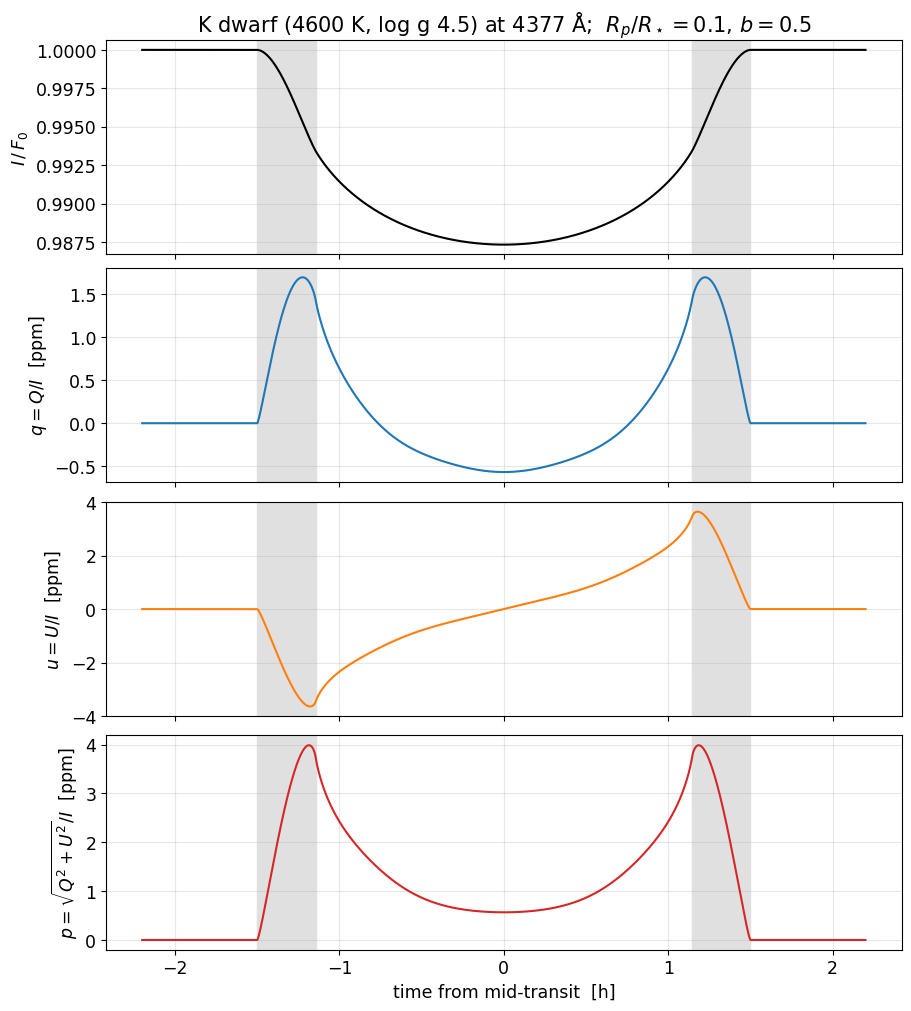

In [6]:
host = tp.LimbPolarizationModel.from_kb2015(teff=4600, logg=4.5, wavelength=4377, grid=grid)
rp, b, t14 = 0.1, 0.5, 3.0 / 24  # radius ratio, impact parameter, duration [days]
orbit = TransitOrbit(period=3.0, duration=t14, impact_param=b, radius_ratio=rp)
t = np.linspace(-2.2, 2.2, 1501) / 24  # days from mid-transit
th = 24 * t
lc = tp.transit_stokes(host, orbit, t)
t_ingress = 12 * t14 * np.sqrt((1 - rp) ** 2 - b**2) / np.sqrt((1 + rp) ** 2 - b**2)  # 2nd contact [h]
fig, ax = plt.subplots(4, 1, figsize=(9, 10), sharex=True, constrained_layout=True)
for a, yv, lab, c in zip(ax, [lc.I, 1e6 * lc.q, 1e6 * lc.u, 1e6 * lc.p],
                         [r"$I\,/\,F_0$", r"$q = Q/I$  [ppm]", r"$u = U/I$  [ppm]", r"$p = \sqrt{Q^2+U^2}/I$  [ppm]"],
                         ["k", "C0", "C1", "C3"]):
    a.plot(th, yv, color=c)
    a.set_ylabel(lab)
    for s in (-1, 1):
        a.axvspan(s * t_ingress, s * 12 * t14, color="0.88", zorder=0)
ax[-1].set_xlabel("time from mid-transit  [h]")
ax[0].set_title(r"K dwarf (4600 K, log g 4.5) at 4377 Å;  $R_p/R_\star = 0.1$, $b = 0.5$");

## 4. Different stellar types

The next figure keeps the same planet and geometry but swaps the host star among the four types from Section 1, all at the $B$-band pivot. The trends follow K&B: cooler and lower-gravity atmospheres have relatively more scattering opacity high up compared with H$^-$ absorption, so their limbs are more strongly polarised. Bluer wavelengths behave the same way, because Rayleigh scattering scales as $\lambda^{-4}$. The photometric transits (top) are nearly identical, with depths within about 10 % of each other, but the polarimetric signal (bottom) changes by an order of magnitude. The K giant is there to show the trend. A real planet transiting a giant would have a far smaller $R_p/R_\star$, and the signal scales roughly as $(R_p/R_\star)^2$.

stellar types:   0%|          | 0/4 [00:00<?, ?it/s]

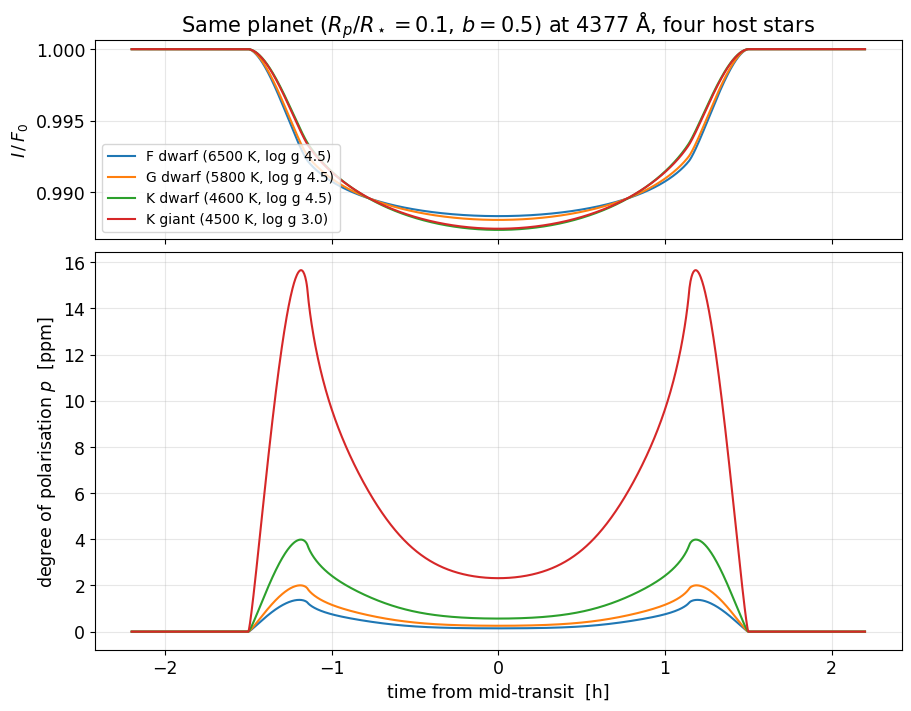

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [1, 2]}, constrained_layout=True)
for (label, (teff, logg)), c in zip(tqdm(types.items(), desc="stellar types"), plt.cm.tab10.colors):
    m = tp.LimbPolarizationModel.from_kb2015(teff, logg, wavelength=4377, grid=grid)
    lc_type = tp.transit_stokes(m, orbit, t)
    ax[0].plot(th, lc_type.I, color=c, label=label)
    ax[1].plot(th, 1e6 * lc_type.p, color=c)
ax[0].set(ylabel=r"$I\,/\,F_0$", title=r"Same planet ($R_p/R_\star = 0.1$, $b = 0.5$) at 4377 Å, four host stars")
ax[0].legend(fontsize=10, loc="lower left")
ax[1].set(xlabel="time from mid-transit  [h]", ylabel=r"degree of polarisation $p$  [ppm]");

### How much does the unknown extreme limb ($\mu < 0.1$) matter?

K&B tabulate nothing below $\mu = 0.1$ ($r > 0.995$), so the polynomials extrapolate there. One way to measure how much that matters is to change the degree of $g$. That changes the extrapolation (the cell prints $\mathcal{Q}(0)/\mathcal{Q}(0.1)$ for each degree) while fitting the tabulated points about equally well. Degrees of 7 and above overfit the ten points, giving $g(1) < 0$, and the fitting function refuses them. The lower panel shows the difference from the default degree 6.

What to look for: the ingress and egress peaks, where the limb dominates, move by less than 1 %, so the unknown extreme limb hardly matters. The mid-transit values move by up to about 0.1 ppm (roughly 20 % there). That spread comes from near disk centre, not the limb: at mid-transit this planet sits at $\mu \approx 0.87$, where K&B tabulate only $\mu$ = 0.5, 0.7 and 0.9, so polynomials of different degree are free to differ between those points. Treat mid-transit $p$ at the ~20 % level as model-dependent.

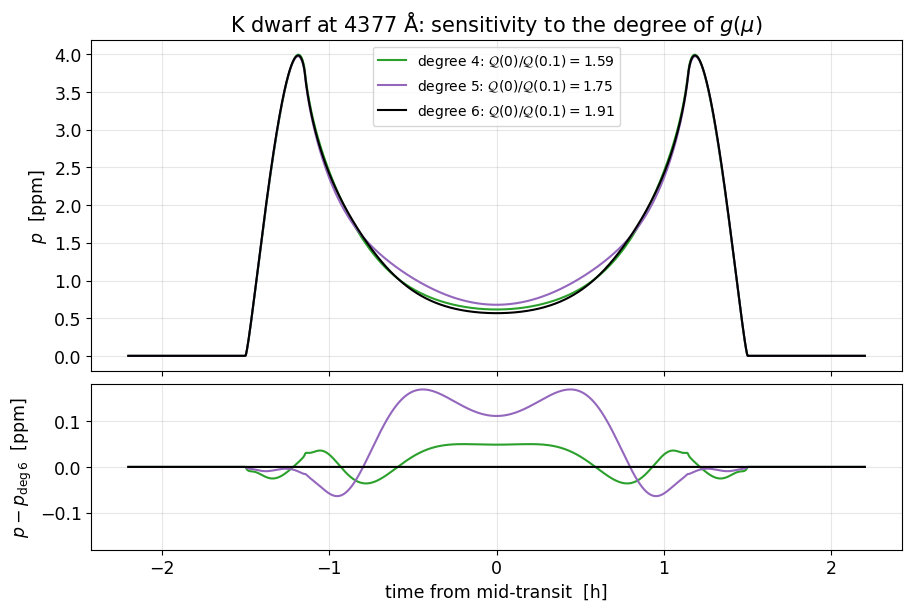

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}, constrained_layout=True)
p_ref = np.asarray(lc.p)  # degree 6, from Section 3
for deg, c in zip([4, 5, 6], ["C2", "C4", "k"]):
    m = tp.LimbPolarizationModel.from_kb2015(4600, 4.5, wavelength=4377, grid=grid, polarization_degree=deg)
    p_deg = np.asarray(tp.transit_stokes(m, orbit, t).p)
    ratio = float(m.polarized_intensity(0.0) / m.polarized_intensity(0.1))
    ax[0].plot(th, 1e6 * p_deg, color=c, label=rf"degree {deg}: $\mathcal{{Q}}(0)/\mathcal{{Q}}(0.1) = {ratio:.2f}$")
    ax[1].plot(th, 1e6 * (p_deg - p_ref), color=c)
lim = np.abs(ax[1].get_ylim()).max()
ax[1].set_ylim(-lim, lim)
ax[0].set(ylabel=r"$p$  [ppm]", title="K dwarf at 4377 Å: sensitivity to the degree of $g(\\mu)$")
ax[0].legend(fontsize=10)
ax[1].set(xlabel="time from mid-transit  [h]", ylabel=r"$p - p_{\rm deg\,6}$  [ppm]");

## 5. Is it detectable? A photon-noise-limited simulation

`tp.simulate_transit_observation` turns a model into data. The host's Vega magnitude in Bessell $B$, $V$ or $R$ is converted to AB with the Bessell & Murphy (2012) offsets, and the photon rate is $(3631\,{\rm Jy}\times10^{-0.4\,m_{\rm AB}}/h)\times(\Delta\lambda_{\rm FWHM}/\lambda_{\rm pivot})\times A\times T$ for collecting area $A$ and total throughput $T$. In a dual-beam polarimeter every photon counts towards $I$, so $\sigma(I/F_0) = 1/\sqrt{N}$ per exposure. The normalised Stokes parameter $q$ is measured only during the fraction $f$ of each exposure spent on $Q$ (default $f = 0.5$, the other half on $U$), so $\sigma_q = 1/(\epsilon\sqrt{fN})$ with modulation efficiency $\epsilon$. Only photon noise is included: no read noise, sky, scintillation or instrumental systematics. Real polarimeters hit a systematic floor at the ppm level, so these numbers are a best case.

The target is an HD 189733-like system, built from approximate literature values that you should check against current catalogues before quoting: a K dwarf host with $T_{\rm eff}\approx5050$ K, $\log g\approx4.6$ and $B\approx8.6$, and a planet with $R_p/R_\star\approx0.155$, $b\approx0.66$, $P\approx2.219$ d and $T_{14}\approx1.83$ h. The telescope is 4 m with a 0.3 central obstruction, and the total throughput of 0.3 is a placeholder for your instrument's real value. Exposures are 60 s over ±2.4 h. The figure shows one simulated transit in 10-minute bins with the noise-free model, and below each panel the z-scores (data − model)/σ.

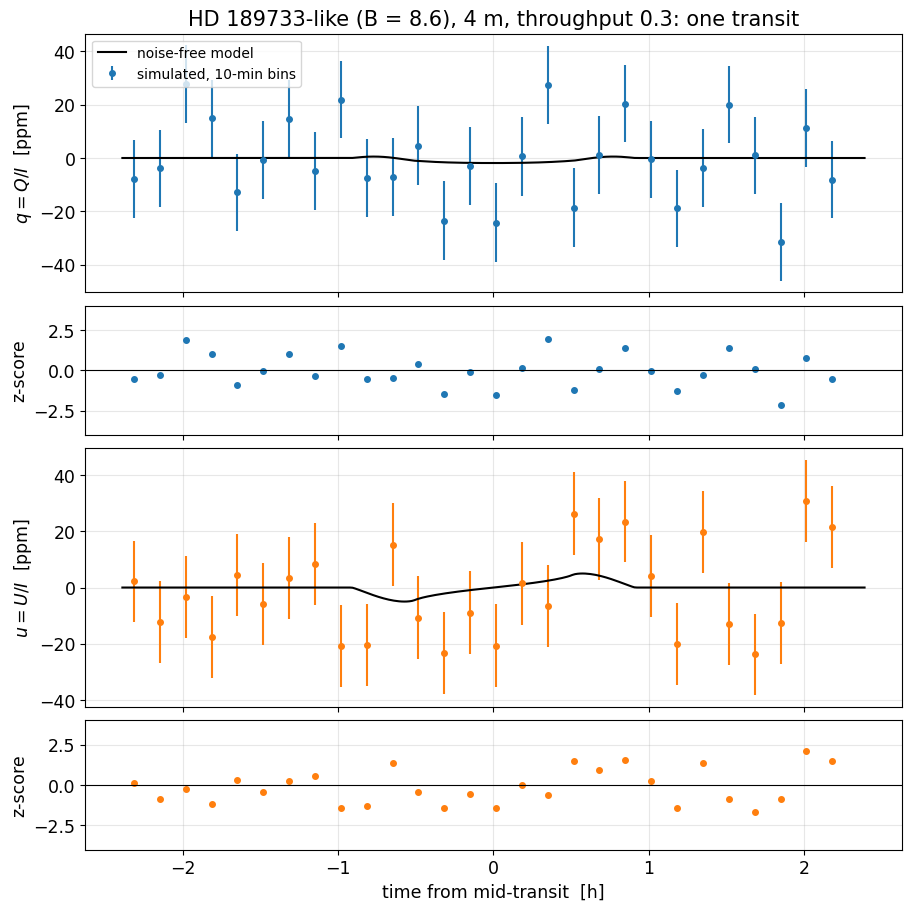

In [9]:
hd189733 = tp.LimbPolarizationModel.from_kb2015(teff=5050, logg=4.6, wavelength=tp.BESSELL_BANDS["B"].pivot_wavelength, grid=grid)
orbit_hd = TransitOrbit(period=2.21857, duration=1.83 / 24, impact_param=0.66, radius_ratio=0.155)
obs = dict(vega_mag=8.6, band="B", aperture_diameter=4.0, central_obstruction=0.3, throughput=0.3,
           exposure_time=60.0, t_start=-0.1, t_end=0.1, seed=42)
sim = tp.simulate_transit_observation(hd189733, orbit_hd, **obs)
fig, ax = plt.subplots(4, 1, figsize=(9, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 2, 1]}, constrained_layout=True)
for i, (key, c) in enumerate([("q", "C0"), ("u", "C1")]):
    tb, yb, sb = tp.bin_data(sim["t"], sim[f"{key}_obs"], sim[f"sigma_{key}"], 10)
    _, mb, _ = tp.bin_data(sim["t"], sim[key], sim[f"sigma_{key}"], 10)
    ax[2 * i].errorbar(24 * tb, 1e6 * yb, 1e6 * sb, fmt="o", ms=4, color=c, label="simulated, 10-min bins")
    ax[2 * i].plot(24 * sim["t"], 1e6 * sim[key], color="k", label="noise-free model")
    ax[2 * i].set_ylabel(f"${key} = {key.upper()}/I$  [ppm]")
    ax[2 * i + 1].plot(24 * tb, (yb - mb) / sb, "o", ms=4, color=c)
    ax[2 * i + 1].axhline(0, color="k", lw=0.8)
    ax[2 * i + 1].set(ylabel="z-score", ylim=(-4, 4))
ax[0].legend(fontsize=10, loc="upper left")
ax[0].set_title("HD 189733-like (B = 8.6), 4 m, throughput 0.3: one transit")
ax[-1].set_xlabel("time from mid-transit  [h]");

A single transit is clearly not enough. To put a number on it, the next cell computes the matched-filter signal-to-noise ratio per transit, $\mathrm{SNR}^2 = \sum_i (s_i/\sigma_i)^2$, after projecting out a constant offset in $q$ and $u$. Real data always carry such an offset, from interstellar and instrumental polarisation. It then combines $q$ and $u$ (independent measurements) and gives the number of transits needed for a $5\sigma$ detection, $N = (5/\mathrm{SNR})^2$, for a few apertures at the same throughput.

In [10]:
print(f"{'aperture':>9} | {'photons/60 s':>12} {'sigma_q/60 s':>12} | {'SNR(q)':>6} {'SNR(u)':>6} {'SNR(q,u)':>8} | transits for 5 sigma")
for diameter in [2.0, 4.0, 8.0, 39.0]:
    s = tp.simulate_transit_observation(hd189733, orbit_hd, **{**obs, "aperture_diameter": diameter})
    snr_q, snr_u = tp.matched_filter_snr(s["q"], s["sigma_q"]), tp.matched_filter_snr(s["u"], s["sigma_u"])
    snr = np.hypot(snr_q, snr_u)
    print(f"{diameter:7.1f} m | {s['photons_per_exposure']:12.2e} {1e6 * s['sigma_q'][0]:9.1f} ppm | "
          f"{snr_q:6.2f} {snr_u:6.2f} {snr:8.2f} | {int(np.ceil((5 / snr) ** 2)):5d}")

 aperture | photons/60 s sigma_q/60 s | SNR(q) SNR(u) SNR(q,u) | transits for 5 sigma
    2.0 m |     2.36e+08      92.0 ppm |   0.13   0.33     0.36 |   199
    4.0 m |     9.46e+08      46.0 ppm |   0.26   0.66     0.71 |    50
    8.0 m |     3.78e+09      23.0 ppm |   0.52   1.32     1.42 |    13
   39.0 m |     8.99e+10       4.7 ppm |   2.53   6.45     6.92 |     1


## Summary

K&B's tables map onto jaxoplanet with two ingredients. The intensity table is already normalised to $I(1)$, which is what `calc_poly_coeffs` expects. For polarisation, the quantity to fit is the limb-frame polarised intensity $\mathcal{Q} = (Q/I)\,(I/I(1)) = (1-\mu^2)\,g(\mu)$, not the degree $Q/I$. Degree-6 polynomials reproduce all 625 tabulated models to near the tables' rounding. In the sky frame the two Stokes maps are $-g(\mu)(x^2-y^2)$ and $-2g(\mu)xy$, single $l=2$ spherical harmonics times a limb-darkening-like polynomial, so starry occults them exactly, provided you multiply back in the limb-darkening normalisation $F_v$ that `surface_light_curve` divides out and normalise by the same $F_0$ as the photometry.

The resulting signal is a few ppm for a hot Jupiter around a K dwarf in the blue, peaking at ingress and egress, with $Q$ symmetric and $U$ antisymmetric about mid-transit. It grows strongly towards cooler, lower-gravity hosts and shorter wavelengths. The peaks are insensitive to how the untabulated $\mu<0.1$ limb is extrapolated, while mid-transit values are uncertain at the ~20 % level because the tables are sparse at $\mu>0.5$. In the photon-noise limit, an HD 189733-like system needs tens of transits on a 4 m telescope for a $5\sigma$ detection, or a handful on an ELT. The instrumental systematic floor, which is not modelled here, is likely to be the real limit.